# Exploratory Data Analysis

In [1]:
import os
import sys

sys.path.append('../src')

import dask.dataframe as dd
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from data_loader import (
    download_dataset,
    load_orders,
    load_interactions,
    load_items,
    load_categories
)

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

## Вспомогательные функции

In [2]:
def plot_orders_per_day(ddf: dd):
    
    data = ddf.copy()
    data['created_date'] = dd.to_datetime(data['created_date'])
    daily_orders = data.groupby('created_date').size().compute()

    sns.set(style="whitegrid", font_scale=1.2, palette="muted")
    plt.figure(figsize=(10, 5))
    sns.lineplot(x=daily_orders.index, y=daily_orders.values, color="#4C72B0")
    plt.title("Количество заказов по дням", fontsize=16, weight='bold')
    plt.xlabel("Дата")
    plt.ylabel("Количество заказов")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [3]:
def plot_orders_status(ddf: dd):

    status_counts = ddf['last_status'].value_counts().compute()
    status_counts_df = pd.DataFrame(status_counts.sort_values(ascending=False))
    status_counts_df['percentage'] = status_counts_df['count'].apply(
        lambda x: f"{x/status_counts_df['count'].sum():.2%}")
    status_counts_df.index.name = None

    sns.set(style="whitegrid", font_scale=1.2, palette="muted")

    plt.figure(figsize=(8, 5))
    bar_width = 0.4  # уже стандартного
    sns.barplot(x=status_counts.index, y=status_counts.values, color="#55A868", width=bar_width)

    plt.title("Распределение статусов заказов", fontsize=16, weight='bold')
    plt.xlabel("Статус")
    plt.ylabel("Количество заказов")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [4]:
def plot_distribution(df: dd,
                      limit_cnt: int=1_000_000_000,
                      log_scale: bool=False,
                      data_title: str=''):
    
    if log_scale:
        log_scale = (True, False)
        log_title = " (логарифмическая шкала)"
    else:
        log_scale = None
        log_title = ""
        
    data = df.groupby('user_id').size().compute()

    sns.set(style="whitegrid", font_scale=1.2)
    plt.figure(figsize=(10, 6))
    
    ax = sns.histplot(data[data<limit_cnt], bins=50, color="#4C72B0",
                      alpha=0.75, log_scale=log_scale)

    # Добавим линии среднего и медианы
    mean_val = data.mean()
    median_val = data.median()
    plt.axvline(mean_val, color='red', linestyle='--', linewidth=2,
                label=f'Среднее: {mean_val:.1f}')
    plt.axvline(median_val, color='green', linestyle='-.', linewidth=2,
                label=f'Медиана: {median_val:.1f}')

    plt.title(f"Распределение количества {data_title} на пользователя{log_title}",
              fontsize=16, weight='bold', pad=15)
    plt.xlabel(f"Количество {data_title}", fontsize=13)
    plt.ylabel("Число пользователей", fontsize=13)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [5]:
def plot_action_per_hours_week_days(ddf: dd, timestamp_col: str, title: str):
    # Преобразование данных
    data = ddf.copy()
    data[timestamp_col] = dd.to_datetime(data[timestamp_col])
    data['dayofweek'] = data[timestamp_col].dt.day_name()
    data['hour'] = data[timestamp_col].dt.hour

    heatmap_data = (
        data.groupby(['dayofweek', 'hour'])
        .size()
        .compute()
        .unstack(fill_value=0)
    )

    # Упорядочим дни недели
    day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    heatmap_data = heatmap_data.reindex(day_order)

    # Визуализация
    plt.figure(figsize=(12, 4))
    sns.set(style="whitegrid", font_scale=1.1)
    ax = sns.heatmap(
        heatmap_data,
        cmap="YlGnBu",
        linewidths=0.5,
        linecolor="white",
        cbar_kws={'label': 'Количество'}
    )

    ax.set_title(f"{title} пользователей по дням недели и времени суток", fontsize=16, weight='bold', pad=15)
    ax.set_xlabel("Час суток", fontsize=12)
    ax.set_ylabel("День недели", fontsize=12)
    plt.tight_layout()
    plt.show()


In [6]:
def plot_action_types(ddf: dd):
    
    action_counts = ddf['action_type'].value_counts().compute()
    action_counts_df = pd.DataFrame(action_counts.sort_values(ascending=False))
    action_counts_df['percentage'] = action_counts_df['count'].apply(
        lambda x: f"{x/action_counts_df['count'].sum():.2%}")
    action_counts_df.index.name = None

    plt.figure(figsize=(8, 5))
    sns.barplot(x=action_counts.index, y=action_counts.values, color="#C44E52")
    plt.title("Распределение типов действий", fontsize=16, weight='bold')
    plt.xlabel("Тип действия")
    plt.ylabel("Количество действий")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    

## Загрузка датасета

In [7]:
download_dataset()

Downloading: 100%|██████████| 37.4G/37.4G [39:57<00:00, 15.6MB/s]  
Unzipping: 100%|██████████| 3139/3139 [02:29<00:00, 20.95file/s] 


Датасет загружен


## Анализ данных

### Информация о заказах:
- ml_ozon_recsys_train_final_apparel_orders_data
- archive_extra_orders_data/archive_extra_orders_data

#### Информация о заказах с 1 января по 1 июля:
- ml_ozon_recsys_train_final_apparel_orders_data

In [8]:
# В каталоге ml_ozon_recsys_train_final_apparel_orders_data 5 parquet файлов
os.listdir('../data/raw/ml_ozon_recsys_train_final_apparel_orders_data')

['part-00000-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00001-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00002-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00003-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00004-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 '_SUCCESS']

In [9]:
orders_ddf = load_orders(train=True)
orders_ddf.head()

,item_id,user_id,created_timestamp,last_status,last_status_timestamp,created_date
0,15535,3423970,2025-01-11 19:20:02.550,delivered_orders,2025-01-16 10:53:03,2025-01-11
1,15535,1207601,2025-03-25 13:11:48.240,canceled_orders,2025-03-29 08:32:43,2025-03-25
2,119241,2340021,2025-05-03 20:46:18.146,canceled_orders,2025-05-12 17:10:27,2025-05-03
3,119241,2356390,2025-05-01 17:53:00.716,delivered_orders,2025-05-14 14:36:20,2025-05-01
4,119241,1490080,2025-04-22 22:59:11.160,canceled_orders,2025-04-26 06:27:28,2025-04-22


In [10]:
print("АНАЛИЗ ЗАКАЗОВ")
print("=" * 50)
print("Общее количество заказов: {:,}".format(orders_ddf.shape[0].compute()))
print("Уникальных пользователей: {:,}".format(orders_ddf['user_id'].nunique().compute()))
print("Уникальных товаров:       {:,}".format(orders_ddf['item_id'].nunique().compute()))
print("Период данных:            {} - {}".format(
    orders_ddf['created_date'].min().compute(),
    orders_ddf['created_date'].max().compute()
    ))
print("Количество дублей:        {:,}".format(
    orders_ddf.groupby(orders_ddf.columns.tolist())
      .size()
      .map_partitions(lambda s: (s > 1).sum())
      .sum()
      .compute()))
print("Количество пропусков:     {:,}".format(orders_ddf.isna().sum().sum().compute()))
print("\nРаспределение статусов заказов:")
status_counts = orders_ddf['last_status'].value_counts().compute()
status_counts_df = pd.DataFrame(status_counts.sort_values(ascending=False))
status_counts_df['percentage'] = status_counts_df['count'].apply(
    lambda x: f"{x/status_counts_df['count'].sum():.2%}")
status_counts_df.index.name = None
print(status_counts_df)

АНАЛИЗ ЗАКАЗОВ
Общее количество заказов: 18,887,122
Уникальных пользователей: 834,137
Уникальных товаров:       4,673,763
Период данных:            2025-01-01 - 2025-07-01
Количество дублей:        138,019
Количество пропусков:     0

Распределение статусов заказов:
                    count percentage
delivered_orders  9936249     52.61%
canceled_orders   7990577     42.31%
proccesed_orders   960296      5.08%


In [11]:
print("Дубли - вероятно, несколько одинаковых позиций в заказе")
df = orders_ddf.compute()
df[df.duplicated(keep=False)].sort_values(['user_id','item_id','created_timestamp']).head(10)

Дубли - вероятно, несколько одинаковых позиций в заказе


,item_id,user_id,created_timestamp,last_status,last_status_timestamp,created_date
2556463,264778815,1,2025-02-17 20:08:40.530,delivered_orders,2025-02-20 20:05:06,2025-02-17
2556464,264778815,1,2025-02-17 20:08:40.530,delivered_orders,2025-02-20 20:05:06,2025-02-17
3203823,145229551,210,2025-01-15 13:14:51.986,canceled_orders,2025-02-13 08:01:25,2025-01-15
3203824,145229551,210,2025-01-15 13:14:51.986,canceled_orders,2025-02-13 08:01:25,2025-01-15
2402155,187052809,270,2025-01-18 14:46:28.656,delivered_orders,2025-01-22 18:44:43,2025-01-18
2402156,187052809,270,2025-01-18 14:46:28.656,delivered_orders,2025-01-22 18:44:43,2025-01-18
613806,174922942,280,2025-05-08 23:14:15.650,delivered_orders,2025-05-10 15:30:10,2025-05-08
613807,174922942,280,2025-05-08 23:14:15.650,delivered_orders,2025-05-10 15:30:10,2025-05-08
613801,174922942,280,2025-05-09 21:08:55.173,delivered_orders,2025-05-11 18:46:42,2025-05-09
613802,174922942,280,2025-05-09 21:08:55.173,delivered_orders,2025-05-11 18:46:42,2025-05-09


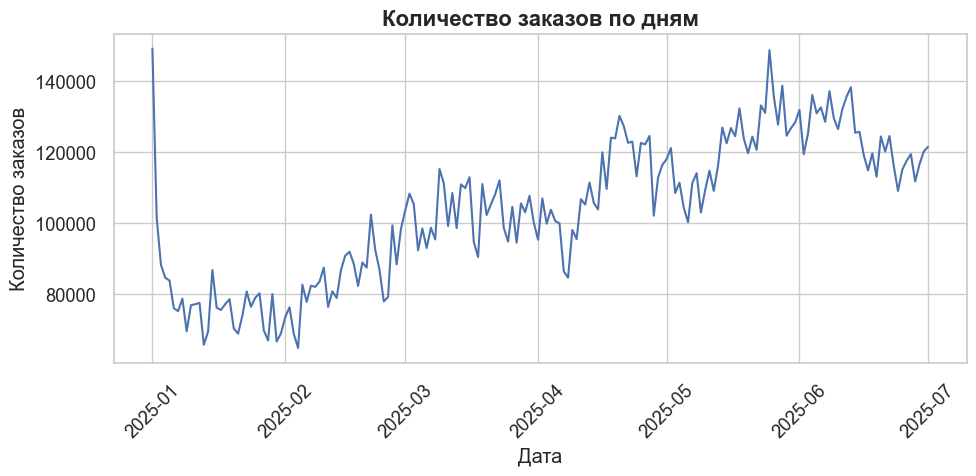

In [12]:
plot_orders_per_day(orders_ddf)

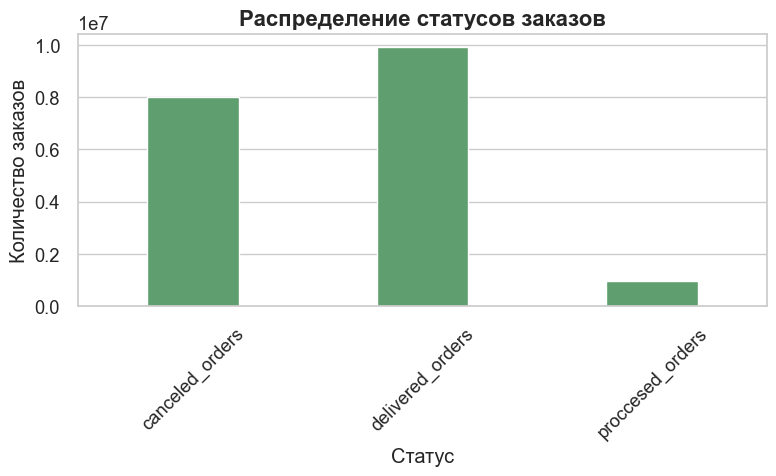

In [13]:
plot_orders_status(orders_ddf)

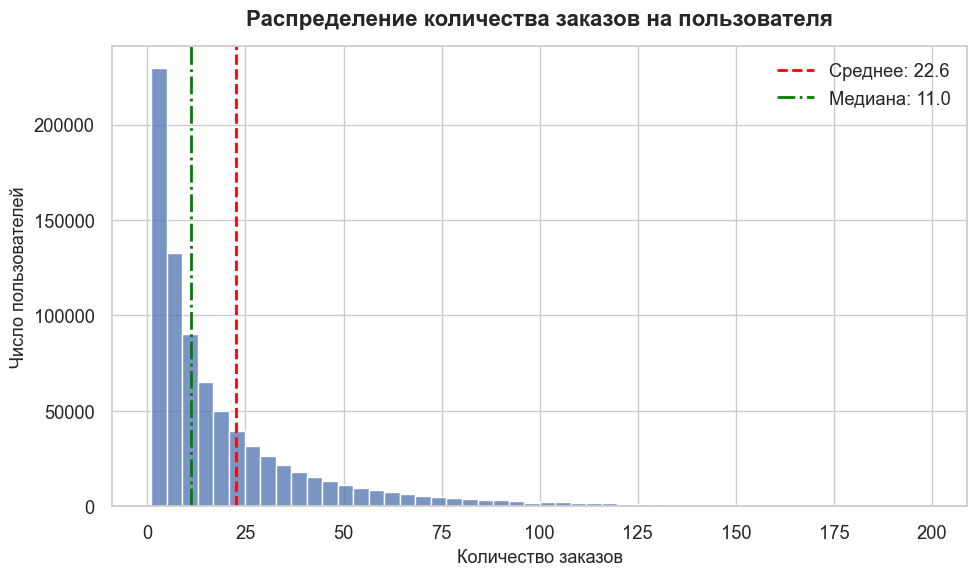

In [14]:
plot_distribution(orders_ddf, 200, False, 'заказов')

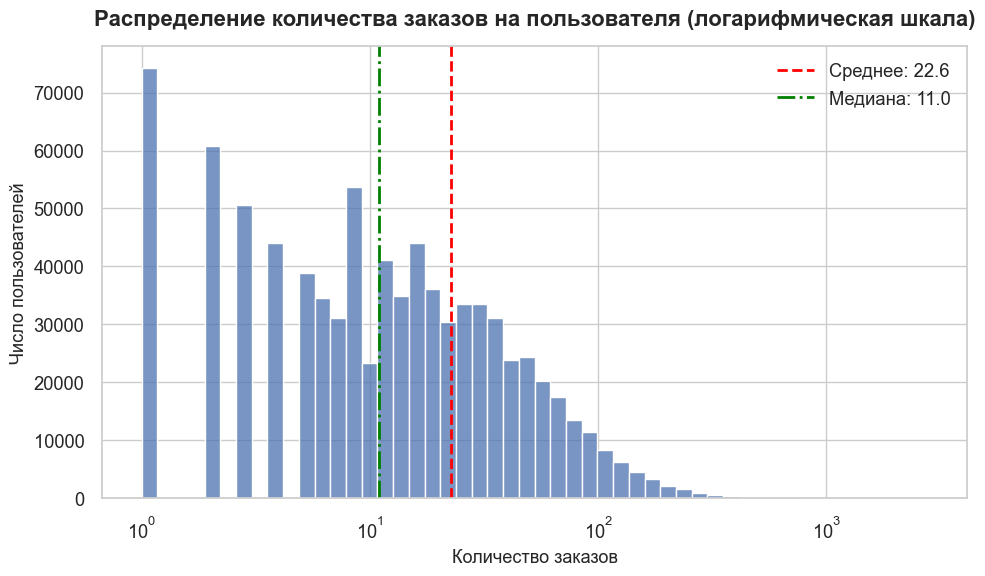

In [15]:
plot_distribution(orders_ddf, 1_000_000_000, True, 'заказов')

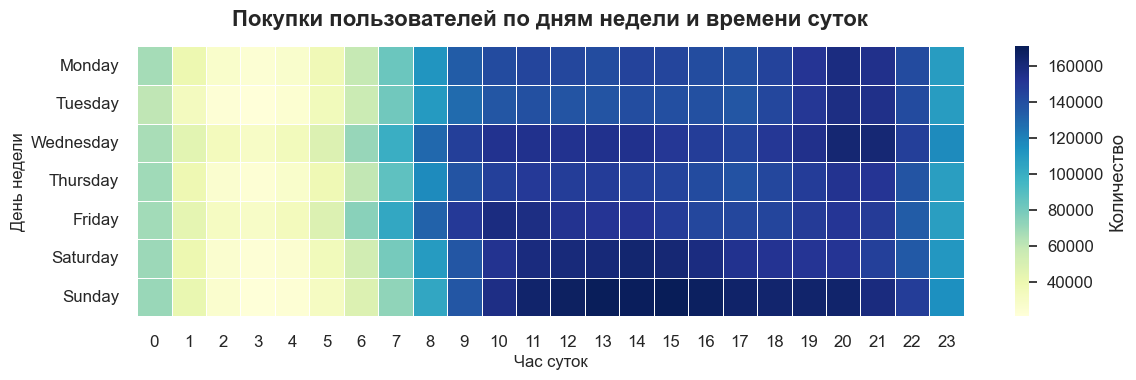

In [16]:
plot_action_per_hours_week_days(orders_ddf, "created_timestamp", "Покупки")

#### Информация о заказах с 2 по 15 июля:
- archive_extra_orders_data/final_apparel_orders_data_07

In [17]:
# В каталоге archive_extra_orders_data/final_apparel_orders_data_07 14 партиций (по датам)
orders_files_new = os.listdir('../data/raw/archive_extra_orders_data/final_apparel_orders_data_07')
for partition in orders_files_new:
    print('В партиции {} {} parquet файла'.format(
        partition, len(os.listdir(f'../data/raw/archive_extra_orders_data/final_apparel_orders_data_07/{partition}'))
    ))

В партиции created_date=2025-07-02 2 parquet файла
В партиции created_date=2025-07-03 2 parquet файла
В партиции created_date=2025-07-04 2 parquet файла
В партиции created_date=2025-07-05 2 parquet файла
В партиции created_date=2025-07-06 2 parquet файла
В партиции created_date=2025-07-07 2 parquet файла
В партиции created_date=2025-07-08 2 parquet файла
В партиции created_date=2025-07-09 2 parquet файла
В партиции created_date=2025-07-10 2 parquet файла
В партиции created_date=2025-07-11 2 parquet файла
В партиции created_date=2025-07-12 2 parquet файла
В партиции created_date=2025-07-13 2 parquet файла
В партиции created_date=2025-07-14 2 parquet файла
В партиции created_date=2025-07-15 2 parquet файла


In [18]:
orders_new_ddf = load_orders(train=False)
orders_new_ddf.head()

,item_id,user_id,created_timestamp,last_status,last_status_timestamp,created_date
0,7510328,981,2025-07-02 08:27:17.686,delivered_orders,2025-07-06 16:14:12,2025-07-02
1,136809690,4670,2025-07-02 17:17:30.423,canceled_orders,2025-07-06 19:35:07,2025-07-02
2,232878073,12341,2025-07-02 15:17:46.393,canceled_orders,2025-07-11 15:36:40,2025-07-02
3,42322137,12860,2025-07-02 00:40:52.503,delivered_orders,2025-07-04 19:44:48,2025-07-02
4,22480781,15330,2025-07-02 07:25:11.226,delivered_orders,2025-07-03 20:07:33,2025-07-02


In [19]:
print("АНАЛИЗ ЗАКАЗОВ")
print("=" * 50)
print("Общее количество заказов: {:,}".format(orders_new_ddf.shape[0].compute()))
print("Уникальных пользователей: {:,}".format(orders_new_ddf['user_id'].nunique().compute()))
print("Уникальных товаров:       {:,}".format(orders_new_ddf['item_id'].nunique().compute()))
print("Период данных:            {} - {}".format(
    dd.to_datetime(orders_new_ddf["created_date"]).min().compute().date(),
    dd.to_datetime(orders_new_ddf["created_date"]).max().compute().date()
    ))
print("Количество дублей:        {:,}".format(orders_new_ddf.compute().duplicated().sum()))
print("Количество пропусков:     {:,}".format(orders_new_ddf.isna().sum().sum().compute()))
print("\nРаспределение статусов заказов:")
status_counts_new = orders_new_ddf['last_status'].value_counts().compute()
status_counts_new_df = pd.DataFrame(status_counts_new.sort_values(ascending=False))
status_counts_new_df['percentage'] = status_counts_new_df['count'].apply(
    lambda x: f"{x/status_counts_new_df['count'].sum():.2%}")
status_counts_new_df.index.name = None
print(status_counts)

АНАЛИЗ ЗАКАЗОВ
Общее количество заказов: 1,475,216
Уникальных пользователей: 346,759
Уникальных товаров:       692,335
Период данных:            2025-07-02 - 2025-07-15
Количество дублей:        0
Количество пропусков:     0

Распределение статусов заказов:
last_status
canceled_orders     7990577
delivered_orders    9936249
proccesed_orders     960296
Name: count, dtype: int64[pyarrow]


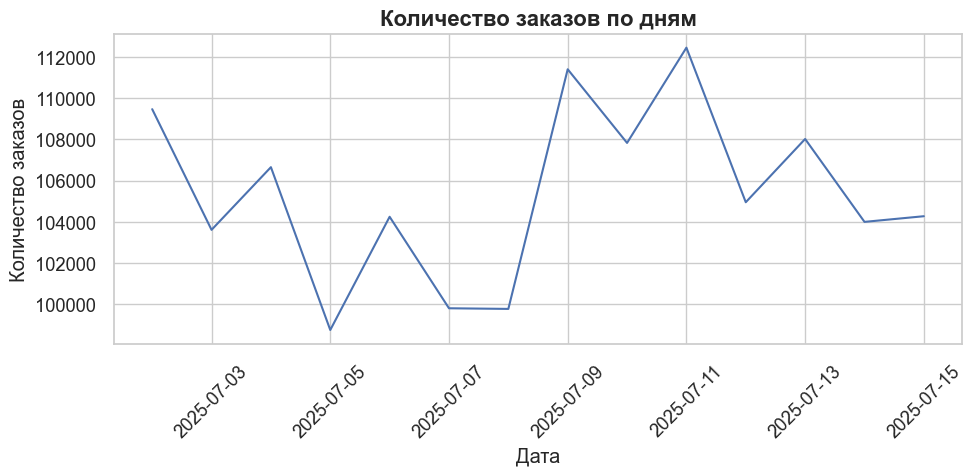

In [20]:
plot_orders_per_day(orders_new_ddf)

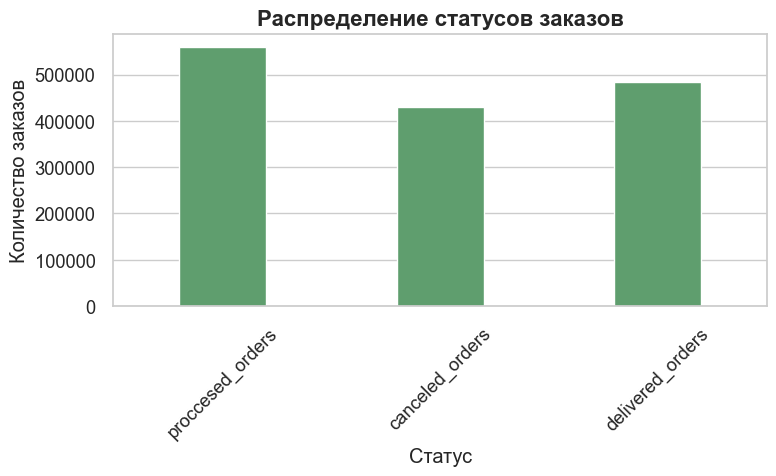

In [21]:
plot_orders_status(orders_new_ddf)

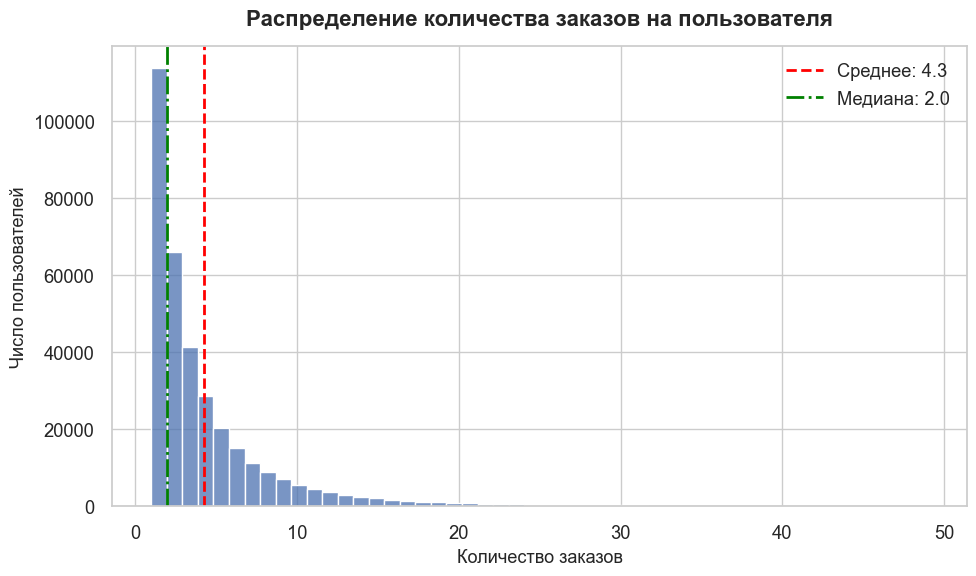

In [22]:
plot_distribution(orders_new_ddf, 50, False, 'заказов')

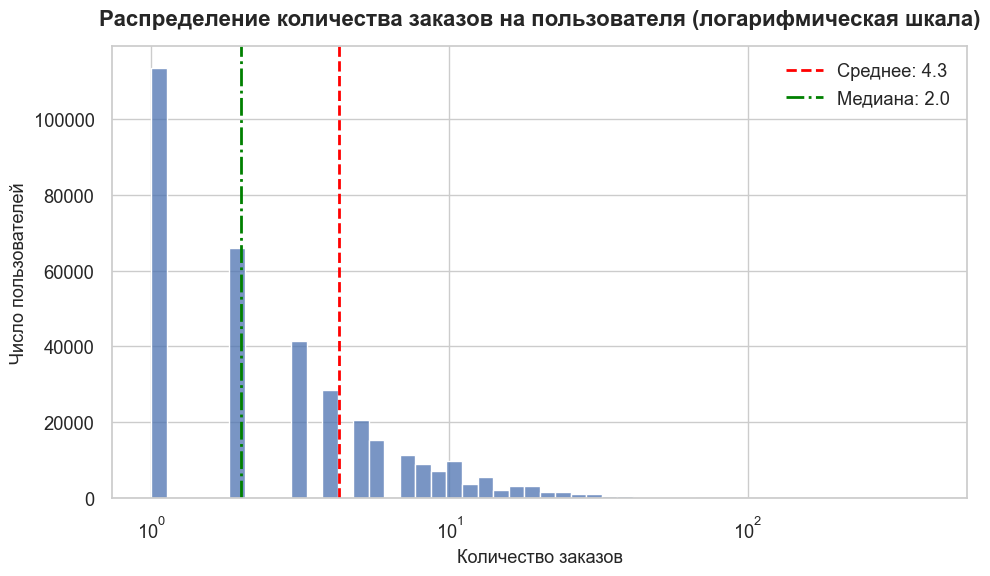

In [23]:
plot_distribution(orders_new_ddf, 1_000_000_000, True, 'заказов')

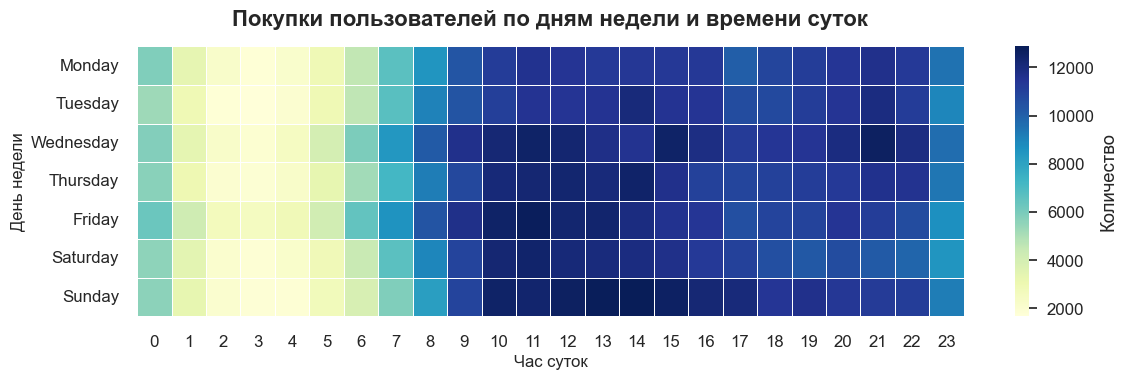

In [24]:
plot_action_per_hours_week_days(orders_new_ddf, "created_timestamp", "Покупки")

### Информация о взаимодействиях:
- ml_ozon_recsys_train_final_apparel_tracker_data
- final_apparel_tracker_data_08_action_widget

#### Информация о взаимодействиях с 1 января по 1 июля:
- ml_ozon_recsys_train_final_apparel_tracker_data

In [25]:
# В каталоге ml_ozon_recsys_train_final_apparel_tracker_data 200 parquet файлов
tracker_files = os.listdir('../data/raw/ml_ozon_recsys_train_final_apparel_tracker_data')
len(tracker_files)
tracker_files[-5:]

['part-00196-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 'part-00197-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 'part-00198-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 'part-00199-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 '_SUCCESS']

In [26]:
tracker_ddf = load_interactions(train=True)
tracker_ddf.head()

,item_id,user_id,timestamp,action_type,action_widget,date
0,678602,4211601,2025-05-05 18:11:15,page_view,cart.cartSplit,2025-05-05
1,678602,4211601,2025-05-05 18:12:57,view_description,pdp.characteristics,2025-05-05
2,678602,4211601,2025-05-05 18:12:52,view_description,pdp.richContent,2025-05-05
3,678602,4211601,2025-05-05 10:39:08,page_view,cart.cartSplit,2025-05-05
4,678602,4211601,2025-05-05 18:12:57,view_description,pdp.characteristics,2025-05-05


In [27]:
print("\n АНАЛИЗ ВЗАИМОДЕЙСТВИЙ")
print("=" * 50)
print("Общее количество взаимодействий: {:,}".format(tracker_ddf.shape[0].compute()))
print("Уникальных пользователей:        {:,}".format(tracker_ddf['user_id'].nunique().compute()))
print("Уникальных товаров:              {:,}".format(tracker_ddf['item_id'].nunique().compute()))
print("Период данных:                   {} - {}".format(
    tracker_ddf["date"].min().compute(),
    tracker_ddf["date"].max().compute()
    ))
print("Количество пропусков:            {:,}".format(tracker_ddf.isna().sum().sum().compute()))
print("\nРаспределение типов действий:")
action_counts = tracker_ddf['action_type'].value_counts().compute()
action_counts_df = pd.DataFrame(action_counts.sort_values(ascending=False))
action_counts_df['percentage'] = action_counts_df['count'].apply(
    lambda x: f"{x/action_counts_df['count'].sum():.2%}")
action_counts_df.index.name = None
print(action_counts_df)


 АНАЛИЗ ВЗАИМОДЕЙСТВИЙ
Общее количество взаимодействий: 1,644,982,482
Уникальных пользователей:        1,011,099
Уникальных товаров:              4,895,557
Период данных:                   2025-01-01 - 2025-07-01
Количество пропусков:            57,565,950

Распределение типов действий:
                       count percentage
page_view         1176606537     71.53%
view_description   221879384     13.49%
review_view         76459985      4.65%
to_cart             61059905      3.71%
favorite            51948578      3.16%
remove              37207155      2.26%
unfavorite          19820938      1.20%


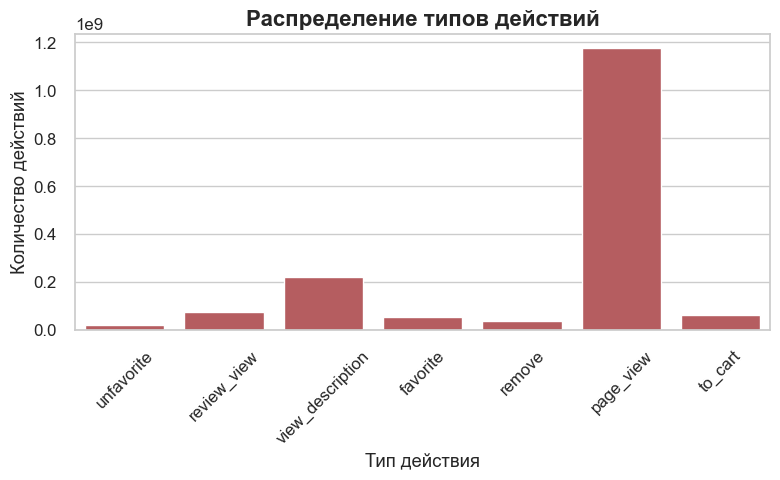

In [28]:
plot_action_types(tracker_ddf)

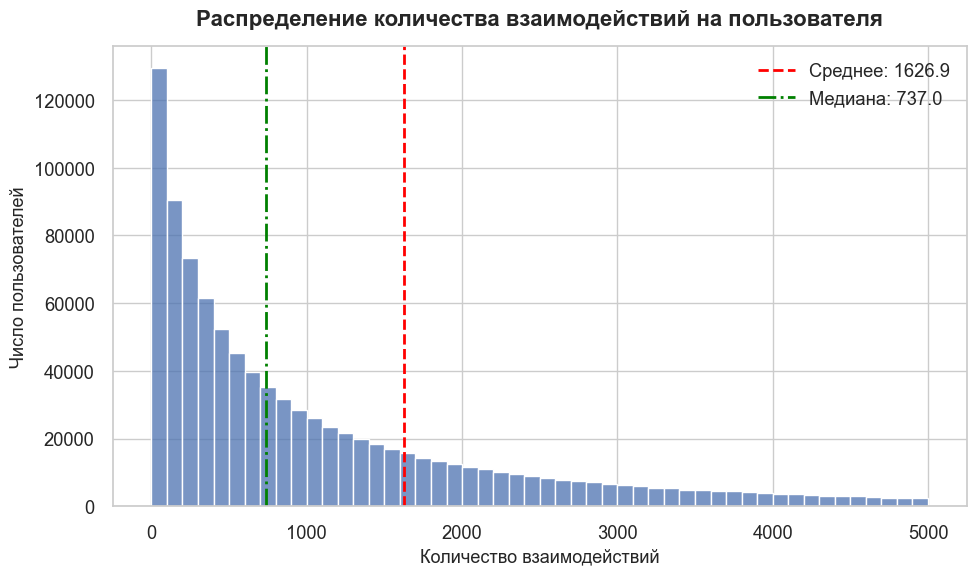

In [29]:
plot_distribution(tracker_ddf, 5000, False, 'взаимодействий')

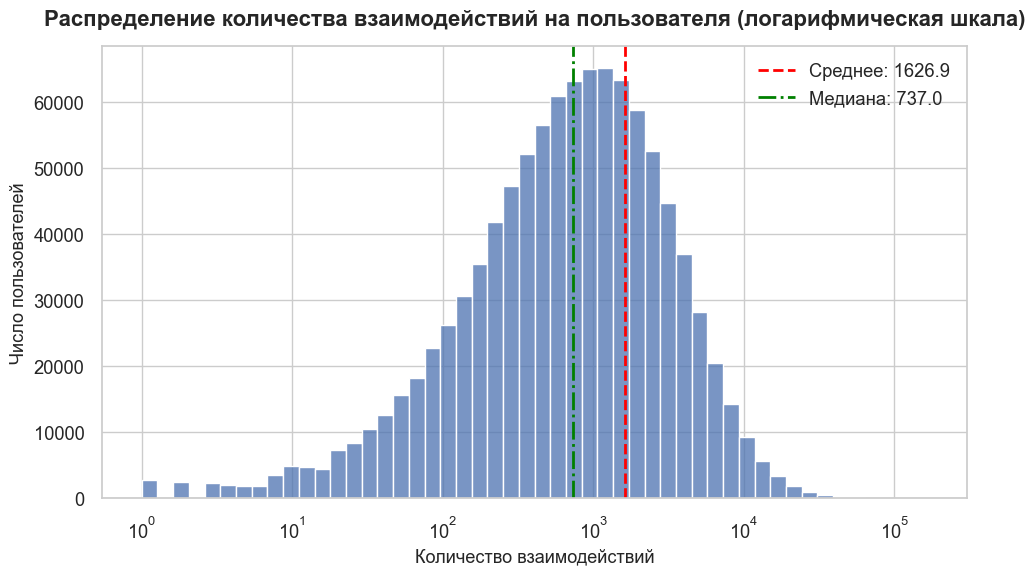

In [30]:
plot_distribution(tracker_ddf, 1_000_000_000, True, 'взаимодействий')

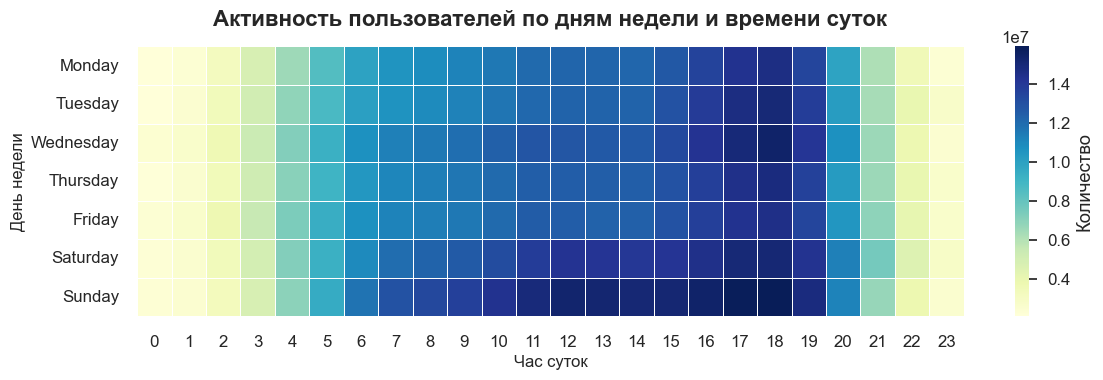

In [31]:
plot_action_per_hours_week_days(tracker_ddf, "timestamp", "Активность")

In [32]:
# Имеются некорректные timestamp взаимодействий
print('Количество записей из прошлого: {}'.format(
    tracker_ddf[tracker_ddf['timestamp'] <= '2024-12-31'].shape[0].compute()))
tracker_ddf[tracker_ddf['timestamp'] <= '2023-12-31'].head(3, npartitions=-1)

Количество записей из прошлого: 3783


,item_id,user_id,timestamp,action_type,action_widget,date
7152743,275406581,4625880,2019-04-28 07:04:24,view_description,pdp.webCharacteristics,2025-04-28
7152755,275406581,4625880,2019-04-28 07:04:24,page_view,shelf.buyTogether,2025-04-28
217062,203708971,3534281,2022-02-20 02:14:05,view_description,pdp.webCharacteristics,2025-06-28


In [33]:
# Имеются некорректные timestamp взаимодействий
print('Количество записей из будущего: {}'.format(
    tracker_ddf[tracker_ddf['timestamp'] >= '2025-07-02'].shape[0].compute()))
tracker_ddf[tracker_ddf['timestamp'] >= '2026-01-01'].head(3, npartitions=-1)

Количество записей из будущего: 2363


,item_id,user_id,timestamp,action_type,action_widget,date
2037137,220466124,834400,2027-02-04 00:57:00,page_view,shelf.analogShelf,2025-06-23
2037138,220466124,834400,2027-02-04 00:57:03,view_description,pdp.webCharacteristics,2025-06-23
2037144,220466124,834400,2027-02-04 00:57:01,view_description,pdp.webCharacteristics,2025-06-23


#### Информация о взаимодействиях с 2 по 15 июля:
- final_apparel_tracker_data_08_action_widget

In [34]:
# В каталоге final_apparel_tracker_data_08_action_widget 14 партиций (по датам)
tracker_new_files = os.listdir('../data/raw/final_apparel_tracker_data_08_action_widget')
for partition in tracker_new_files:
    print('В партиции {} {} parquet файлов'.format(
        partition, len(os.listdir(f'../data/raw/final_apparel_tracker_data_08_action_widget/{partition}'))
    ))

В партиции date=2025-07-02 200 parquet файлов
В партиции date=2025-07-03 200 parquet файлов
В партиции date=2025-07-04 200 parquet файлов
В партиции date=2025-07-05 200 parquet файлов
В партиции date=2025-07-06 200 parquet файлов
В партиции date=2025-07-07 200 parquet файлов
В партиции date=2025-07-08 200 parquet файлов
В партиции date=2025-07-09 200 parquet файлов
В партиции date=2025-07-10 200 parquet файлов
В партиции date=2025-07-11 200 parquet файлов
В партиции date=2025-07-12 200 parquet файлов
В партиции date=2025-07-13 200 parquet файлов
В партиции date=2025-07-14 200 parquet файлов
В партиции date=2025-07-15 200 parquet файлов


In [35]:
tracker_new_ddf = load_interactions(train=False)
tracker_new_ddf.head()

,action_widget,item_id,user_id,timestamp,action_type,date
0,pdp-widget,191536,3824171,2025-07-02 10:33:46,to_cart,2025-07-02
1,catalog.searchResultsV2,191536,3765270,2025-07-02 13:02:49,page_view,2025-07-02
2,catalog.searchResultsV2,191536,3824171,2025-07-02 10:33:42,page_view,2025-07-02
3,shelf.analogShelfPersonal,936816,2118320,2025-07-02 11:24:32,page_view,2025-07-02
4,pdp-widget,1150122,1927141,2025-07-02 14:55:15,to_cart,2025-07-02


In [36]:
print("\n АНАЛИЗ ВЗАИМОДЕЙСТВИЙ")
print("=" * 50)
print("Общее количество взаимодействий: {:,}".format(tracker_new_ddf.shape[0].compute()))
print("Уникальных пользователей:        {:,}".format(tracker_new_ddf['user_id'].nunique().compute()))
print("Уникальных товаров:              {:,}".format(tracker_new_ddf['item_id'].nunique().compute()))
print("Период данных:                   {} - {}".format(
    dd.to_datetime(tracker_new_ddf["date"]).min().compute().date(),
    dd.to_datetime(tracker_new_ddf["date"]).max().compute().date()
    ))
print("Количество пропусков:            {:,}".format(tracker_new_ddf.isna().sum().sum().compute()))
print("\nРаспределение типов действий:")
action_counts_new = tracker_new_ddf['action_type'].value_counts().compute()
action_counts_new_df = pd.DataFrame(action_counts_new.sort_values(ascending=False))
action_counts_new_df['percentage'] = action_counts_new_df['count'].apply(
    lambda x: f"{x/action_counts_new_df['count'].sum():.2%}")
action_counts_new_df.index.name = None
print(action_counts_new_df)


 АНАЛИЗ ВЗАИМОДЕЙСТВИЙ
Общее количество взаимодействий: 116,537,514
Уникальных пользователей:        807,653
Уникальных товаров:              3,197,872
Период данных:                   2025-07-02 - 2025-07-15
Количество пропусков:            0

Распределение типов действий:
                     count percentage
page_view         80595085     69.16%
view_description  17253961     14.81%
review_view        5729054      4.92%
to_cart            4613925      3.96%
favorite           3454652      2.96%
remove             3007494      2.58%
unfavorite         1883343      1.62%


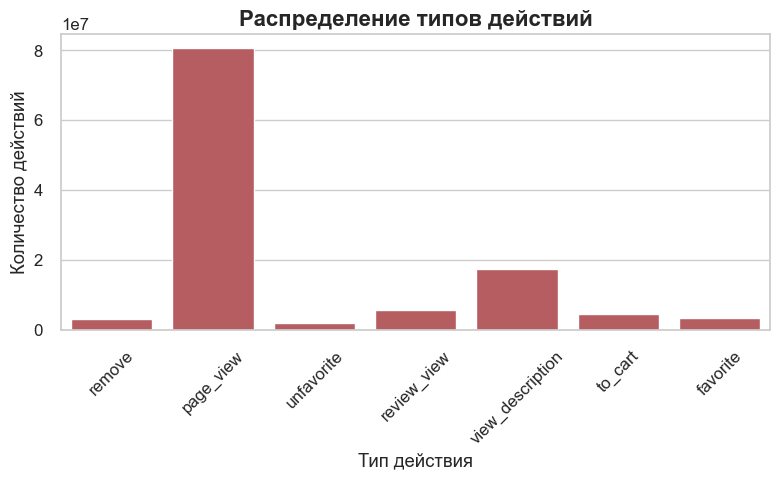

In [37]:
plot_action_types(tracker_new_ddf)

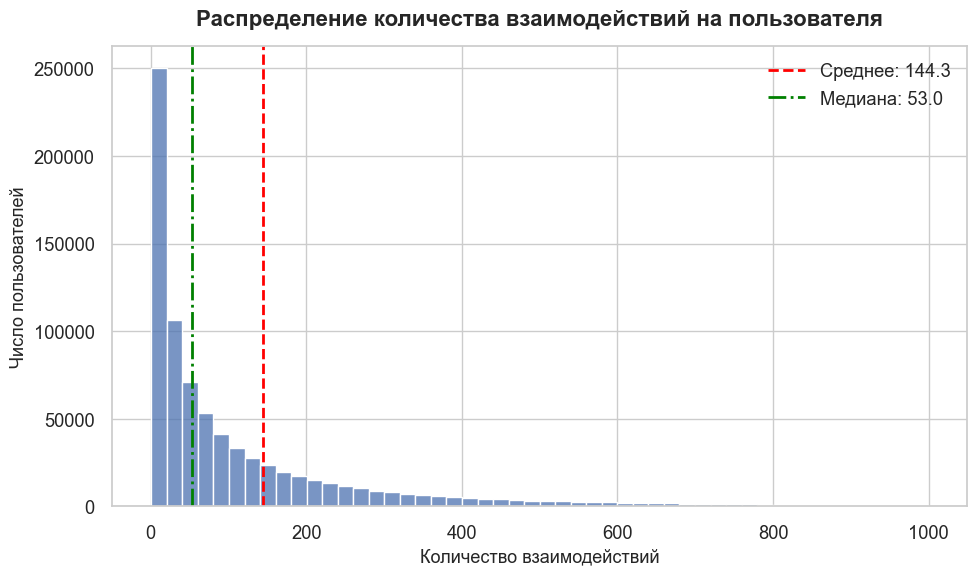

In [38]:
plot_distribution(tracker_new_ddf, 1_000, False, 'взаимодействий')

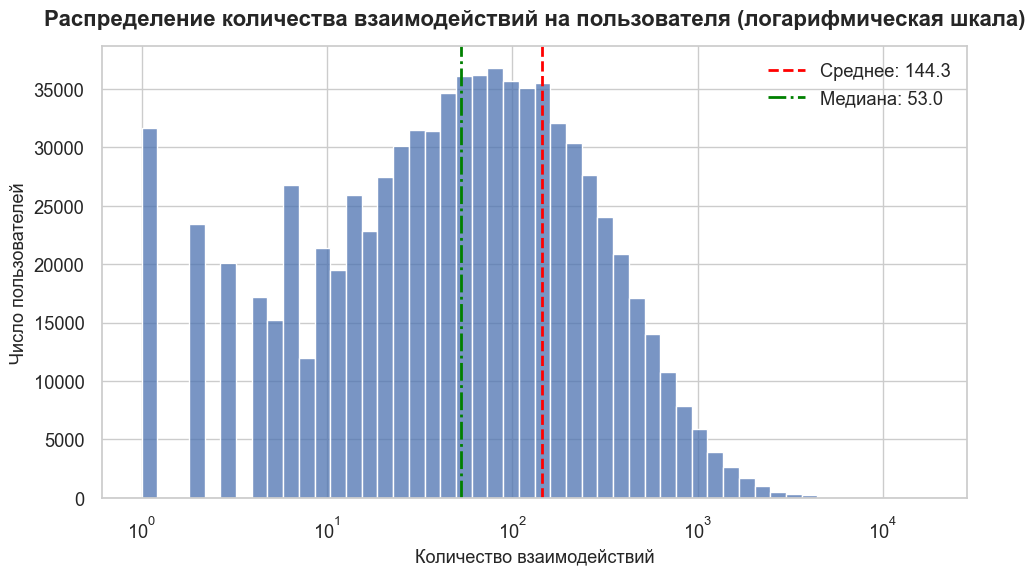

In [39]:
plot_distribution(tracker_new_ddf, 1_000_000_000, True, 'взаимодействий')

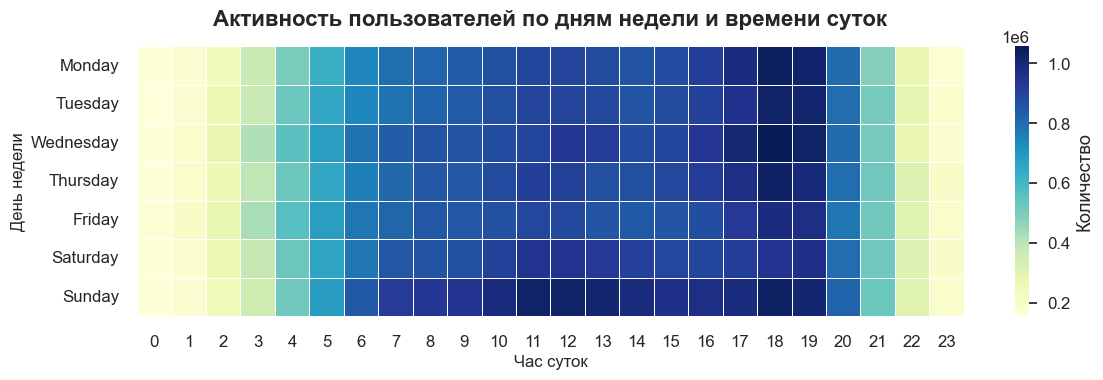

In [40]:
plot_action_per_hours_week_days(tracker_new_ddf, "timestamp", "Активность")

In [41]:
# Имеются некорректные timestamp взаимодействий
print('Количество записей из прошлого: {}'.format(
    tracker_new_ddf[tracker_new_ddf['timestamp'] <= '2025-07-01'].shape[0].compute()))
tracker_new_ddf[tracker_new_ddf['timestamp'] <= '2025-06-01'].head(3, npartitions=-1)

Количество записей из прошлого: 926


,action_widget,item_id,user_id,timestamp,action_type,date
19207,pdp.webCharacteristics,205234237,3467850,2025-04-11 12:58:54,view_description,2025-07-02
19208,shelf.userHistory,205234237,3467850,2025-04-11 12:58:53,page_view,2025-07-02
21613,pdp.webMobRichContent,122015772,3946580,2025-04-27 08:10:00,view_description,2025-07-02


In [42]:
# Имеются некорректные timestamp взаимодействий
print('Количество записей из будущего: {}'.format(
    tracker_new_ddf[tracker_new_ddf['timestamp'] >= '2025-07-16'].shape[0].compute()))
tracker_new_ddf[tracker_new_ddf['timestamp'] >= '2025-07-16'].head(3, npartitions=-1)

Количество записей из будущего: 1181


,action_widget,item_id,user_id,timestamp,action_type,date
2068,catalog.searchResultsV2,174293145,2283521,2025-07-16 09:16:32,page_view,2025-07-12
21895,catalog.searchResultsV2,138665833,2283521,2025-07-16 12:08:47,page_view,2025-07-12
21896,catalog.searchResultsV2,138665833,2283521,2025-07-16 12:05:55,page_view,2025-07-12


### Информация о товарах:
- ml_ozon_recsys_train_final_apparel_items_data

In [43]:
# В каталоге ml_ozon_recsys_train_final_apparel_items_data 100 parquet файлов
items_files = os.listdir('../data/raw/ml_ozon_recsys_train_final_apparel_items_data')
len(items_files)
items_files[-5:]

['part-00096-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 'part-00097-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 'part-00098-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 'part-00099-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 '_SUCCESS']

In [44]:
items_ddf = load_items()
items_ddf.head()

,item_id,itemname,attributes,fclip_embed,catalogid,variant_id,model_id
0,400301,Очки солнцезащитные,"[{'attribute_name': 'Type', 'attribute_value':...","[0.32023853, 0.11766258, -0.784552, 0.4168199,...",17080,243954236,33306429
1,678602,Футболка GOLDUSTIM Футболка женская,"[{'attribute_name': 'Type', 'attribute_value':...","[0.4360095, 0.6339668, 0.029741853, 0.09847632...",7508,8039633,27057398
2,746401,Худи Patagonia,"[{'attribute_name': 'Type', 'attribute_value':...","[0.47452784, -0.4727797, -0.51971936, -0.08221...",7555,120078071,11645051
3,872829,"Комплект носков adidas 3S C Spw Mid 3P, 3 пары","[{'attribute_name': 'Type', 'attribute_value':...","[-0.06987186, -2.2802832, -0.5829071, -0.33674...",36563,247120069,38088455
4,893255,Жилет Buy & Style жилеты,"[{'attribute_name': 'Type', 'attribute_value':...","[0.12488763, 0.5466293, 0.29031003, 0.21499962...",7535,327822613,19339929


In [45]:
print("\nАНАЛИЗ ТОВАРОВ")
print("=" * 50)
print("Общее количество товаров:      {:,}".format(items_ddf.shape[0].compute()))
print("Количество уникальных товаров: {:,}".format(items_ddf['item_id'].nunique().compute()))
print("Товары с названием:            {:,}".format((~items_ddf['itemname'].isna()).sum().compute()))
print("Товары с эмбеддингами:         {:,}".format((~items_ddf['fclip_embed'].isna()).sum().compute()))
print("Количество пропусков:          {:,}".format(items_ddf.isna().sum().sum().compute()))

print("\nТоп-10 категорий:")
top_categories = items_ddf['catalogid'].value_counts().compute().sort_values(ascending=False).head(10)
for cat_id, count in top_categories.items():
    print(f"  Категория  {cat_id}:\t{count:,}")


АНАЛИЗ ТОВАРОВ
Общее количество товаров:      6,439,422
Количество уникальных товаров: 6,342,024
Товары с названием:            6,439,422
Товары с эмбеддингами:         6,439,422
Количество пропусков:          0

Топ-10 категорий:
  Категория  7559:	413,637
  Категория  7508:	267,444
  Категория  36484:	225,336
  Категория  7660:	219,858
  Категория  7502:	199,919
  Категория  7512:	120,846
  Категория  7511:	108,535
  Категория  7530:	106,773
  Категория  17002:	105,158
  Категория  7644:	101,622


### Каталог (категории) товаров:
- ml_ozon_recsys_train_final_categories_tree

In [46]:
# В каталоге ml_ozon_recsys_train_final_categories_tree 1 parquet файл
categories_files = os.listdir('../data/raw/ml_ozon_recsys_train_final_categories_tree')
categories_files

['part-00000-163f9108-23d6-4fd6-98c4-7bcb73ee27e2-c000.snappy.parquet',
 '_SUCCESS']

In [47]:
categories_ddf = load_categories()
categories_ddf.head()

,catalogid,catalogpath,ids
0,15500,"[{'id': 15500, 'name': 'Электроника', 'fullNam...","[15500, -1]"
1,15501,"[{'id': 15501, 'name': 'Телефоны и смарт-часы'...","[15501, 15500, -1]"
2,15502,"[{'id': 15502, 'name': 'Смартфоны', 'fullName'...","[15502, 15501, 15500, -1]"
3,15511,"[{'id': 15511, 'name': 'Аксессуары для смартфо...","[15511, 15501, 15500, -1]"
4,15892,"[{'id': 15892, 'name': 'Чехлы', 'fullName': 'Ч...","[15892, 15511, 15501, 15500, -1]"


In [48]:
print("\nАНАЛИЗ КАТАЛОГА ТОВАРОВ")
print("=" * 50)
print("Количество категорий:            {:,}".format(categories_ddf.shape[0].compute()))
print("Количество уникальных категорий: {:,}".format(categories_ddf['catalogid'].nunique().compute()))
print("Количество пропусков:            {:,}".format(categories_ddf.isna().sum().sum().compute()))


АНАЛИЗ КАТАЛОГА ТОВАРОВ
Количество категорий:            7,012
Количество уникальных категорий: 7,012
Количество пропусков:            0


### Тестовые данные (id пользователей для рекомендаций)
- ml_ozon_recsys_test.snappy.parquet

In [49]:
test_ddf = dd.read_parquet(
    "../data/raw/ml_ozon_recsys_test.snappy.parquet")
test_ddf.head(3)

,user_id
0,1857340
1,4094281
2,4815130


In [50]:
print('Датасет содержит:\n'
'  - {:,} записей\n'
'  - {:,} уникальных пользователей (user_id)\n'.format(
    test_ddf.shape[0].compute(),
    test_ddf['user_id'].nunique().compute()
    ))

Датасет содержит:
  - 470,347 записей
  - 470,347 уникальных пользователей (user_id)



## Разделение на обучающую и тестовую выборку

Тестовые данные содержат только user_id и не представляется возможным оценить качество рекомендаций для будущего периода.

Для обучения будет использованны данные о заказах и взаимодействиях с 1 января 2025 по 1 июля 2025

Для оценки будет использованны данные о заказах и взаимодействиях с 2 по 15 июля 2025